# 바이오산업을 위한 양자머신러닝
### 분자 구조에서 용해도 예측까지 · 국민대학교 세미나 실습 · 2026-10-28

**데이터 불러오기 → 선형 회귀 → 광자 확률 특징 추출 → 확률 특징으로 회귀 학습**

발표에서 본 표와 그림을 직접 만들어 봅니다. 분자 그림, Paracetamol의 예측 기여도,
두 분자의 56개 출력 확률, 실제값–예측값 산점도가 순서대로 나옵니다.

**실행:** Quandela Hub의 Cloud / Web IDE에서 이 `.ipynb`를 열고 **Restart Kernel and Run All Cells**를 선택하세요.
지원되는 Python 커널이 필요하며, 첫 실행은 패키지 설치로 시간이 걸릴 수 있습니다.
`Shift+Enter`로 한 셀씩 진행해도 됩니다. 이 파일에는 데이터가 포함되어 있어 노트북만 업로드해도 됩니다.

**이 실습의 학습 대상:** 광자 회로는 고정하고, 출력 확률을 입력으로 **고전 Ridge 회귀의 계수·절편을 학습**합니다.
양자 회로의 위상을 역전파로 학습하는 QNN 실습은 아닙니다. QPU·토큰·GPU 없이 CPU에서 이상적 광자 회로를 시뮬레이션합니다.
Hub의 Python 환경에서 실행해도 실제 QPU를 사용한 결과가 되지는 않습니다.

**데이터 출처:** Krasnov et al., [BigSolDB 2.2 (Zenodo, 2026)](https://doi.org/10.5281/zenodo.22648301), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). [관련 논문](https://doi.org/10.1038/s41597-025-05559-8). 물·25°C 데이터의 필터링·분자별 집계·특성 계산을 추가했습니다. 원본 파일·저자·가공 기록은 배포 저장소의 [DATA_PROVENANCE.md](https://github.com/Hoon34/Quandela/blob/main/DATA_PROVENANCE.md)에 있습니다. 예측과 그림은 이 세미나의 자체 분석입니다.


## 0. 실행 준비

아래 셀은 현재 커널의 패키지를 확인하고 **없는 패키지만** 설치합니다.
이미 있는 패키지를 일괄 업데이트하지 않습니다. 설치가 필요한 경우 인터넷 연결이 필요합니다.
설치 후 커널 재시작 안내가 나오면 재시작하고 처음부터 실행하세요.
정확한 검증 버전은 배포 폴더의 `requirements-verified.txt`와 마지막 실행 기록에서 확인할 수 있습니다.

In [1]:
import importlib.util, importlib.metadata as metadata
import subprocess, sys

if sys.platform in {"emscripten", "wasi"}:
    raise RuntimeError("이 실습은 PyTorch를 지원하는 일반 Python 커널이 필요합니다. 브라우저 전용 Python 대신 서버 Python 커널을 선택하세요.")
if sys.version_info < (3, 10):
    raise RuntimeError("Python 3.10 이상 커널을 선택하세요.")

AUTO_INSTALL_MISSING = True
PACKAGES = {
    "numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<4",
    "scipy": "scipy>=1.13,<2", "sklearn": "scikit-learn>=1.4,<2",
    "matplotlib": "matplotlib>=3.8,<4", "rdkit": "rdkit>=2024.3",
    "torch": "torch>=2.2,<3", "perceval": "perceval-quandela>=1.3.1,<2",
    "merlin": "merlinquantum>=0.4.2,<0.5", "threadpoolctl": "threadpoolctl>=3.1",
}
missing = [spec for module, spec in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    if not AUTO_INSTALL_MISSING:
        raise RuntimeError("현재 커널에 설치 필요: " + ", ".join(missing))
    print("현재 Python 커널에 설치합니다:", ", ".join(missing), flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    importlib.invalidate_caches()
for name, prefix in [("merlinquantum", "0.4."), ("perceval-quandela", "1.")]:
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        raise RuntimeError(f"{name} 패키지를 이 Python 커널에 설치하세요.")
    if not installed.startswith(prefix):
        raise RuntimeError(f"이 커널의 {name}=={installed}은 이 실습과 API가 다릅니다. requirements.txt의 버전을 설치한 커널을 선택하세요.")
print("Python", sys.version.split()[0], "| 필요한 모듈 확인 완료 | QPU 작업 제출: 0")

Python 3.13.16 | 필요한 모듈 확인 완료 | QPU 작업 제출: 0


### 데이터는 이 노트북 안에 함께 있습니다

접힌 셀에는 공개 데이터와 선택된 회로 설정을 압축해 넣었습니다.
동봉된 `data/`가 있으면 사용하고, 없으면 내장 데이터를 읽습니다. 원본 해시로 내용도 확인합니다.
**저장된 기준 예측은 마지막 검증에만 읽으며 학습에는 사용하지 않습니다.**

In [2]:
from pathlib import Path
from io import BytesIO
import os, json, gzip, base64, hashlib, tempfile, time

# Public BigSolDB-derived data. This payload contains no credentials or external code.
BUNDLED_FILES = {'molecules.csv': {'sha256': 'f853c105d4f713751281bf1c0993ff7db0d4799db5cfbdc921503c399157bd88', 'gzip_base64': '...'}, 'protocol.json': {'sha256': '7b003bf43a62c37dc82361cf50c5c1b1c7d0428e86d9da786747db43ce129a42', 'gzip_base64': 'H4sIAAAAAAAC/5VVW4vcNhR+D+Q/iHlqYHZGki1ftk/NhhJIGsJuoJRQjGwde5TIlivJM2xD/nuP5bmlzRYCgwef66dP5zv+8vwZIStvJ9fA6pasdiGM/na7/RsGq+zGum7roLFO+S3nWVoklK3WMcfoBgYfk+7uyMs/SLqhR1cLMkwOPPo+zgY0/WbN72FxL29vbff+/P7h/cMv55d3U//6lR2s89emextkkLWBl3ZQF8+9Hro7Ow1hNRv+XPr31kAzmQhAiHQxKtiDsWMPGHtL0jRZzLCXZpJB2wGtjLHFap3u9CBN1YP0eJQ5a66WpWIJCNCP4OIxqzfo4GWxYUeft2a/dFkdZAB3ZCVI10G0nvDdHLQH0oPSciC2JQ5G6wIoguQ8/IRR27cvvkmupkHHCsZ2jM4R4Am2mwKQLTE6OCDH7i/WZLDhYpviEY8AR7OU+dVZvGjS2GGAJui9Do83nbPTeKO0/2T1EIiTg7I9iSlr4gHRccozRjk9D0KvQ2RwZmg1vt5iO61Ia10fMfRWgQG1IR92QC58LzXJTipSA6LQgx8RBcRMEuZY6YwGRz6DG8AQHyb1iLHoBvRrj4HG2MPNNG7InR1a3U3uWBobxlJ2MI/4IFe3vyb1FJZ8/M0ABzhgdwUj4APPjBC1ioU25zMOCKaSZtzJeU7ohi4OnHJwe6uvfHBDj4PQRnorjJlMuFLDl+UvTipSEy80NjiNdSw8oopAVVfIq2ZfuT5qjm2SLC8Z42kpGCvSLL2k7qxRdgqXUF4IluQszzljaSL+G9nLJRAvFhVe8ixhGc2K75TkGEc3gvMkZbQUKc59eR14jdY3ssUbUpXHGfT+gielrEhEkmZZngoqkkv6NcGL8ev6Sc7O3P8IbZxmuaCUsySbT/F/rFGWC8SXUC4SJvhTtNFNKXgpEs7TIqe8oPnTvBU8YYlgBZbOi4z9IG+8yFkpioyXGd4mF9/h7Tx80Tw6W8tao8we56o4ZF0kTh6uKGtt87lSGlv7ZQuK7Ej91UpFOciq2cmhi1t19XASWIOrpR9Qig63xCza0WmUrwLfOD2GWcnz1v4ZhUaWJUbQtkj/WG9D7l+9wddLjl+TVhtcnQh4TWTXOegWYeM2OiYfALeAVAoxBBs7n5Y2Gacav05kxnwS8PKFqyKWyu8kF9l8DNZwliuaUZmIJoF5+rNMQsZp2ja5aOsyaco6Rz0UvCwxKc9Uk9OkaKAtS3X6Fs6bab65f5dvC5E0jAqVtjkqUDBesLplDS3LpG1zVVOV5linFk1bq6bkDMetScqSibxWRXEsrxXgp8jrfjKRhWrealg/uAmWiL/Gqfpka1/5qcZtjBczz9vzZ1//ActezhngBwAA'}, 'reservoir_config.json': {'sha256': 'e9e08c8808d2b100ac5d15782b33c517525a2d96e2f0b4ceaf58b05a13097b5e', 'gzip_base64': 'H4sIAAAAAAAC/7WYS2/jNhCA7wvsfxB8bBNjhi+JBfbQx6GHtlhsC/QQLAzFoh0liuhKFJJ0sf99R7H1iO1Elug9iRqSH+fFITBf3r8LgtnS5qt0Pfsp+FL/kmBlYlcVZmGLxBQkv9rKgwAvmpFsR9COWDvi7UhsB593glmabyq32MTOmSIn9GyZVSWNTTJrltyleVLP/FfFuavuW3kWP5mipJmGPrtPHxdxvs4MCXEeilBriRI0clD9NZubuKzXwBwAVMRDzTVIprhiUdhf6OzGZnb9VB9/XaTJ2rSn39vE1Ie3YLtalcYtSmNqbZnSzcTmxjqbv1C0XMbZVgFEwcNIaBZpppChaJbsHb28e7DFXXv6g0nXN658EYt5F4P+GF7I4aicxru41J+vz/JdaEoXO9Od00R8/wv73/qzjfLs2d2LJokomunSlIdIuYdo0qfxmjhxfp83NN/yXlU5j+/7Cs/+tNkfdv2xjcanNF//aqvctRJa8W/398/Hv39uf/6q7n//zeaWUrcn+mTJz/F1Zn6xeVJ+D86AxmfGHVH8wL3bG1MuijjpZcOc7qyWTANyqVDzJmxsHoFmYagxhBC0iJq4UrKjpH/gqAWnS9xcYTmXQrGQViLNQbsB5qGMhIRIA1dCc9ltEAgoJRUMRhOsO4FLRhopHtXHYxQ1qTUXSjKMtCYici5bEICONAIDwQEi2dkQSk3KKjJO0rZ2PVmGSEVIcCZDhT1N6T+MIgU1RqlWI8GF4rW1hJEi6kwIlSD/hEpxJpC1KvE5q4sdCanICMlajcjWWnnGyK/Qd56WEZOSXKiRAdftyUjxEeRQ2qIYE7IX1+bCHJSnriB1I+jJ4EC2K0lNwhT2Or5Os9Q9LWzl6sJ0Z556B1wdPjVw6ujlk3R1+Hzh2UhwKnMEaYA5iXSU6UnqMV8h4cVo5iAJPT3+9n48G2mMx3F0Zg57HE71/QgSevoJTvW9J2manwY8NomEntYNeGwS6aidniQ8m0497V4hwcXot2GQxDyrytu5g2cjjbktMLr64iAJPavK2zcDz0aa5if0rCpvR5x5WjetqsDo926adWOqCox+OX11GlNVTq4vI0jMM8dPri+epDFZcHJVmERCT+vQM8dPvsueJDybTtNyfCDbJ5GYZ+wGsn0SCT1jN5CjniTf2B2NoieJeVp31PeepJ6dvQbnrqlg8qVN0rzudO86UrfBh+C5Nxv8EGx7GFe9tqV5XNx+phlXxGl+ubJZclm6OE/iIkn/N0mQmHJZpBtni+DHYJU+kmjXFL7ddsJmhYkTW7lea70+badCET+0DbM4I4XqLra5BNn1yp0plmZT73dFZZ57te/fff0GBQn1drYXAAA='}, 'reference_predictions.csv': {'sha256': '6a3db032aa01cfba0de599fa855e7f32e4d1366d2001a95eb7b6a3de5e1a9484', 'gzip_base64': 'H4sIAAAAAAAC/6WazWskSZLF7wv7V/QlRZXU/v1xEAwTMPQpNKBjtRia3D4U1GYt1cvC/vf7e2YeqZSqemDYarVSGRlp7m5u9t4z8zj/dvl6+Xz+7cs//vjPz19+/+Pj/378r2+//8fn839//nr5x5fPl99/+3Z75dvvf/z+7X++fv727/+2/bR92v7yEk9Pd5v++uUl8ZuXvG1bedy20+P6hGvFbshc2+7s0kuK2/bxPj30VuNMKdTUQgjz431+GK32MHrNfc4Wev54Xx7CzKmMHmbrYzZGx9S+/bTf7ScsnuP5fD5tX+4u5/jxPj70WJus5FF6bFXjxJZHHSmnUFIvpdi1nNIsvYRSe8uhu1lmHR83LetxS0/njGHG4PL5pP83f81afNLg8fFJM+y5lZy1mshcbSGF+eYSJ2trg6nrtlZnTyPVxDTGaMeQu79gKTyUMjvrnCWHWEvvulZzyawnYqfkEerH8JByazXlWCIDjhKvptzlJ7bhtGver5b7SD2l0nqeIacWdS331GevY47a8PbAckyaYircyK+ev7P8fNjUvdwx0mghzjB9splvxjR7HLlmdoLb2M+e+VfY68rrYfLJtu6cztHe8u70dLhbjtct/BW35F7OpZbMdHEFqzYv11HqnJMrbGIudleszCWXNvoIMdRjNB9M22dhgvO4cbQeap4jJwsdXgfOmAo+hQ6XaitVy2w5snlubbs7Kfxk8bRd0vlyviSfsj65888UZFWOHqWEEQM2LBhnCY1Z45KEq3UtP8g5hXHqDHHM3I9R9htfd32Wa8yK75Dka5wekvYJb7c27VrMbFoNhHucjRA6TD2tPNl290ZaWYP/5eNroJCCZcZRC8PFoHHSQx6RCMedufc+sy4NYjrFivNTILHWKG7EESE+rYi52FD7EwnKRt7Zhyd7tbs0aSIo50p6AgM5hCbPl5RGVNri+RaKLmkPtDFllhTYpTXqkw3rdjcC9e9/edGF048nolsvv7wcc9FXTn+7zuYIyrV/hHDE2WzPiLHrUhmNpK4tWooU272YGokPtHSya6xZ+Xz2mwxMbDkbM9mdGLTxLLyCe6APq8KLw+7KWQESCN40Z3SUWIn86en+5eHd26frf5+23z6kF0MMsI1gSRHP4dBmyAKGxhQyqNR6jebQQEJVALclYeCw6I7ax6e/uwfxbTwcsn3R+gPhlQ3WRgBWtf4UQStB3SBI4jTIBuny6A0scHCS1Wd3cnrjmd3fxsNN8QH/ZL6GM8cg2j0zqwd0qoEAj8MDpLbJpAe5I4T5k2FugoO0zAsDzvnHw0MMdaY6WmKBkVlYtKehYQUxQ5ts3EXGxQD2gpuAxDH4CrXFfkYSV/ozVil+R3UmNMBwoPMvVHnfPyv+3Zd8vcQ8k7wL4FXFSyphFoVlfSCBQi9KDrySmy6BCWkURcKc2cMynnZjN8t+ZT48kbi8nY5Nvnv8tP/y4WUzdntQgH3avnzILyf9eee/9UsuaL2TFKQpOBq6sSr7hvuYHlEVazTAS6AEmN17m8I4m8fjNYYtgeNHcRERC62V3IOWZtsOPlb4KYHSoJIuZeIggRWNl1Zt053qPvIZtEg+Ef29pZks7MErHCFsLbOWarQXUtTegf+wQMuGkdv2bCF/S3UOmU/6UG6Cp99j5ZxgUYCfcyZXs1GGJovHwSfGIOF1LU4AM4MbnZz04c7xq4Pw/qwowKLx3g0brrF3sblCgF+M/uB5iJyZuRGkZB+bbMyS5uiJVAwj6ZIxLyHKO5gTNeELfbq1f7eQrnMnyiQQzKW4jpJIEYuCySFZFoq/m1APVgu2kUdYbofLbv3nwvDJc+/5QMRXaHlNlnXnFcPhJdN2kU2NZcwgvEUx1eKsjG5hR0FmftADPjnois0AJAY6zOFgj+a+N5t68yb5G3Jz5SBhuT2fy4V/heGffV55saVtz92hEm3/g/iQkCQCiAMjCPAVqAXhYXLcZwCJQuPGCUgCWi4i9iX99PvnzfTE4/7zk+liUBqlO4IJqkmUk8QTsWyRbFgOJ6EEeNcB2mZrfVoTO90kt4WO2X69evNx1OSQbjlUUVNnEXapkxdQBPQ/CznpyyKxC0JJ/4HE5XXIw7GLOlEa6eI4a/Iif00eZBDllKhFB4LZ5IYJOKgukdrIF9TttGtDcGtSXSlU+utQkohs0LGCiwQ5b05//XYIdAsb7kukyYPhOYOCCKIiECjEZqNGiEmUjWuH7xFyRoiQCe4K578Z8zZRyG6mThx2UgpU8lTRdsB+aKE61jVuaBGAbBo1ur+WBt3MrM0OtmcmoQwFjH0RsORSG9qBMpbsUSZaVKcYpkwdmbKcvy/lBVsv59wff7zClUCDZELhku3dNBXbjwYGK3Nk0KxMkqhGAFfRO0KyR0v0y9WwOfz+ki8X9vbeNlpsakMZJLYK1EA9bQKtVXylEoufiP6IBiXlAVUHuw/RAhy+RngV/UuiXkDHbMCbpR6jByLQT/DD+al4bCaySwsiWuFF36YG2pYp2C2uDfaF5wbge1zk87jf6GGW8LR9lyjR5ou8YTmd3Y91WMT0Id3DEprKCNMJBFqhfELRIWKKlrX/rLr310/7h5dDsanee9Zc/rjG60UESJIjJyijgGzCyBKdIhLsIPfA9UKsmO7pKHEkEj8krg0SF4LtPmeqkUXzfxwa/zk6w9jEmR80Aa9SmahqIzNhbfafrciGVabhkDqjT3JCNWb3cZQU33loc1ICq2B9eBD0y2Rv9gBLKr+L8ArnmJsoQVkYYd7gEgaR6WuuCT+MFldpcjE2qiJwqAi+ZpMtrwVERQVlU3pYeNek6opUhvSpu7D7msMXM2n8jzae8EmV9oWnrdzA65159yQFlV1qpJTFL+RHZpeVd8pgEfZSCj7Tv62Znjzn8sXGKvLVViQ5DQCXSlEsUZhFqXzgcBbzNSghrVlRUlLuK+I0F+K6IjpNm9vob0Lp/P69QWG8veYOZ1/FohQaEom2L0U1MhIaUIiheaMFTpX6ooIsxipP59usPC/QClWVK/7TSrpyEJAi3dBpUBLijHrIrwEGJGepAsFytbeTzEibu7W1M6hOJ61DsYqCEK+SgrxTRTy6F7tDsIiEUlHQ29XYO3+c4+6rYw0VqsHLXmWrdOGr6CDqSrSYy/hAlcF0ozpLGSV3mL2BoifxiYiZeQUWpP1IrCp5nUrawJNESsUjJjoJJnVBWBIpLc05rlZvsB9rbD4bwy0AWfRCBwvQH5HNVSjQncGmBVxLMI5kuutZmn0//Yya/9lj8I0Xvi6V8rQAk4CuaoZl6tPhdS0WyWk4rJUUPSkhYcBYeAZWa7PeyrO46qVbsfR8dP32xUd2i0EaiH3DUapcvEq1FSHxKeClmtj6bOKVihjdnILgI2SbERkidY1L2E22zqd00zw4vZeQ1rhTtwSILMAZuhweg4oEr0RnVCsKphtiuqDmDhkB4pL66i8ygMf7Fw+k1zyPByJFr27ZcYBByi85BSlLhRdBncZeDPmkNuBRwqtIxxzWdzP+Wm3c1tf1ISCtCW8qKvLIey1vbbd/YtoQ6XRUKMclb3p5F60+4HQJGHBydSpRflPEDNxTwhgQoL2QsErfDDzEZf575FsYbQ4zz4CTyCepdRKspH9p9ufTm0LoOxBTDJBsaCmIzyOEGhDQoaQiyyh+kme0CfCk+ohF5GX9ohy5f/nhAi7x4dP+24cXVUwUcegGiTwKIi/ekHnsRLBml1WhAiMpZhyp0PRaiEEur6hxMS1U1O1FJhYRaM+OiYELESchZLwTqf5lVb1KhZOaT/iyUHJfICnZNgCvGFUPeCkMYIFnqM4+yFprHlFhQ2xkOesHi9Oyxbxuyq4rCHk2NhPGAn08WR3UyLaOcBrFesHJ3ABiNnSCSi70iIICyXbyZi2wcNSCauyYNL+qA2uHPjKai5Jrf43abiCrAmIT1ANaTVbBhFLl1rcIw/SjSClUtYQUqiiR/ScTDPvdbi3nkID5ockOdYetsYabMAyDNnXbDQAaIQ/jd2BFUI0ZO0iwf+qL7HcC1NOv+8pJx4H446s+VVFJM8Qaqy/aktVSU5Nty3HmzaSgZ1HFx30HKvFBiJIJhaEzhOw8ooRhEVR5GaY1TqVGpwSZxDbVQZhvjJ2XvMliOmVw0JmJW1INyjyjhH4v3b0/kWDEDwTMbM3UdlPu3BQOEpuoK5UzCLzpRXhs4iryjjKhDeOqGKygUfuP36LTHaaSf61ijiY0xZ4VVZu9cE9QQSdPAFNJFK2A7w7FIhyIW7Ktcru2wnVkhIih1lcLrphQxlOAFWCO9RCCjh2S0J77BlGAFwjYH/UAfkRr7PCq/WO6etaTpbIdU5oTtaNq0VvCAH62sop4MOhHhLKUMgg5PFduhv6xf6VqhrqwlDC4sv8L/l0se3QRr21UsR+xMjAt15qGkprCRQDJtO4cTrKjEtBoqPEuR79VPx6bKgmaztOSHFlWS5YII6b5Hp/69FpRx15QzyRjfbX25UeAzq1sD7qv6A/TKkB3V4s8EK1HS5GlMwiok3QkcbV5Q6DXswz7lQ6apmxC82RyvQCrXqAFYSN7RbxFr3Z5b2duUXBv4PLn9t+SHQw2KdKta9Zy+f/ZF1B+ebWu9q1QI4spUJBe87w1X/6J+Rv7bl5Ak9axFBIv1m5VmnjaArCDWwQgWNUIRa/chp2zKNkYrF1Nm8QOOuGEFtHiCKgIQnkVxRS1Y9SrZKMHz1BVpm5+VXfYo+IiRl5HCshSyBYsRZqFko+TOMngVrT61e8HqYiMbqeAWaJahAIwPL0tATTHdRYMCka4F7xnn6bjJxUEw5AdU+TpQKh6mPTV7EittizfpKyfGPniD3F997TdnhUJEsiEiROJZ7ukHUkyPqfOt6wVSISTxFL0FerwkdQBlJJ/Ry9ANunB6iviY1EJZNNCku7hX3ARxMTJSdUa6hoeJu2Y6D0uCDxZP9ke1I6JrflxESNI/qtrzx/CBUoatXFYTVbJ82rVdcSrqwWNV/VUi9p76ihCsDqi5RqG0ToRwwJjdfoBbqIYiESCWl14owxWEX0AEKXMV2/AEB+IUUIFPVldWQIdVZW84G21rtSDwx2UoEOF7VvT70rFeHUKiqnoyBRhhbnpxxbqiALekxICbLckge3VhoVUVTi9Mf7VD9QZWB1A1lVVgfohBoao5u2YZHgnHSitA5VczctuKW7rwYn9euT2129eYQa2ChboqmhL95wZIu2mnC/TG+AqGuD+2JQph83tpl/zuO/uSzUAkbnakurVX9As0Uo6QsguZXSihGavCcHQisdV3BFMb/34uK+eiopK5DgiFrs+SQI46hREXdZqzuDDIYzI0nxdR7iyuiBKWHV047xw2azn7qVFUQ8mqi4qqXmnnXBgjCBVyiS9da0DAECNeUT1/TBvddC1RWwNEn8CZArzplpWzU9QVM1JLAx1pas3q6yPi5gEfNQvs5T1btrRClsHA2/e3DQPoTBkLjUJUGltLz9kF7qSdnaKaT0gZfnUAYF6ZWlqHHP0a6qd9teKX4gkNnqHfR/vm7VnoPU8Q6IamO4qdbZ1ho2DSrAHJRCJajFPhVDw/X0z3sVAzzYX4cpsg9FoKavHUTEl2rBnUJrBtoJPPSUWIIz7M5NvhYAecFFTNarUx+/Tn8/RYbKKUCBfAOQnwzWVJn0h+Htv/XJeDSryGXzXE0UqaVja9PKlNiIPjEz2tMrq0wB9szbqC/L9nc8vxiQuzptKr6CQouZqLqmJbDWPBmHfczCwG3qohHQhUZNWI4OsV6teIbgeP3B6SqqLKX0wgJj07q6ekoHvg7rlwQcn59WaVAFcenObR4Bd+Ik6TTzfpzcspUgQVOoMXs3N4I3GKd2qmEYJjuhPJaEP+RlByjku81cgXs8+gcPW+b/2E5JESrUOOwBJLpWRvebNiN5RIAB71KpIWwhUyUydUed3A5z/xDRMyQyJt4q+Gv6YDAJhqu8IzUQ7CiyoAkrx0HUgNv0BnWV9k7vXAMvj6HJQxKq1pKcgLOcJa3B4RG8XNkOWlqM6CBRH6JFwePziW7iMwT81kWFTQ1NJJS/vUWw6sxoqCtMqsxz+dUJYirrSOqc5rQdl3navrg/FqIJlqjpBZPP528ILckHRigeQGJCMyJTwCXoOjCzUgbasf9cde30ORnrmB12zdcPdd/21TVOpejyvqIAELlvVqWxCmHTjL0WRWmmdyihK9EmjKvDtsO7L3ZI0yVWZHf6E0dTL1VMzzfBQZ9cN32RWRnWbjMt1YkdqDiITg9ktrh6Xh6WdPh0Bag/m3X36+kEpgCTZvghciirfLPKluCL4/OhADxggDwKInv1xwKFnZVAt4CT5beCydDTSbP9VRfbz3a6nADZ7CsAzx6QIU0Z+ZFfoElUqz3UOHWLyxyRKsyTXQUXW0wavQueyFqGXcrGXaiFb774We0rlOD3tFHRZKSUyiUniv+qIBrggFnB+DfYgCEttOnkbeopGYPF/sUkxe+cpAAA='}}

def asset_bytes(name):
    info = BUNDLED_FILES[name]
    path = Path.cwd() / "data" / name
    raw = path.read_bytes() if path.exists() else gzip.decompress(base64.b64decode(info["gzip_base64"]))
    if hashlib.sha256(raw).hexdigest() != info["sha256"]:
        raise ValueError(f"{name}이 배포본과 다릅니다. data 파일을 복구하거나 노트북만 새 폴더에서 실행하세요.")
    return raw

RUNTIME = Path(tempfile.gettempdir()) / "kookmin-qml-demo-perceval"
(RUNTIME / "logs").mkdir(parents=True, exist_ok=True)
os.environ["PCVL_PERSISTENT_PATH"] = str(RUNTIME)
for key in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ.setdefault(key, "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, SVG
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from threadpoolctl import threadpool_limits

_thread_limit = threadpool_limits(limits=1)
OUT = Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
FEATURES = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumRotatableBonds", "RingCount"]
FEATURE_LABELS = ["Molecular weight", "MolLogP", "TPSA", "H-bond donors", "Rotatable bonds", "Ring count"]
GRAY, PURPLE, ORANGE = "#85949F", "#5648ED", "#DD7B63"
plt.rcParams.update({"figure.dpi":110, "font.family":"DejaVu Sans", "font.size":11,
                     "axes.spines.top":False, "axes.spines.right":False})
protocol = json.loads(asset_bytes("protocol.json"))
encoding = json.loads(asset_bytes("reservoir_config.json"))
print("내장 데이터와 회로 설정 준비 완료")

내장 데이터와 회로 설정 준비 완료


## 1. 데이터 불러오기: 한 행은 분자 하나

우리가 예측할 값은 **물·25°C에서의 로그 용해도**입니다.
BigSolDB 2.2의 문헌 측정 기록에서 물·298.15 K·평형 실험 기록을 고르고,
유효한 645개 측정값을 같은 분자별 로그 용해도의 중앙값으로 집계해 **분자 554개**를 만들었습니다.

- 입력: SMILES에서 계산한 분자 특성 6개
- 정답: $y=\log_{10}(S)$, $S$는 **용매 1 L당 용질의 몰수**. 용액 1 L 기준과 구별합니다.
- 예: $y=-1$이면 $S=0.1$, $y=-3$이면 $S=0.001$입니다.
- pH·고체 형태는 모델 입력에 포함하지 않았습니다. 이 예제는 소분자 수용해도이며 항체 정제 데이터는 아닙니다.

**출처:** Krasnov et al., [BigSolDB 2.2, Zenodo (2026)](https://doi.org/10.5281/zenodo.22648301),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Filtered, aggregated and processed. 관련 논문: [Scientific Data (2025)](https://doi.org/10.1038/s41597-025-05559-8).
각 분자 행의 `source_dois`에는 원래 측정 논문 DOI가 남아 있습니다.

In [3]:
data = pd.read_csv(BytesIO(asset_bytes("molecules.csv")), keep_default_na=False)
assert len(data) == 554
assert np.isfinite(data[FEATURES + ["y"]].to_numpy(float)).all()

EXAMPLE_NAMES = ["Paracetamol", "Naringenin", "Vanillin", "Salicylic acid", "Thiourea"]
# Exact names in the released molecule table are checked below.
examples = data.set_index("name").loc[EXAMPLE_NAMES].reset_index()
example_table = examples[["name", "MolWt", "y", "measurement_count"]].copy()
example_table["S (mol/L solvent)"] = np.power(10.0, example_table.y)
display(example_table[["name", "MolWt", "S (mol/L solvent)", "y", "measurement_count"]].round(6))
print(f"측정 기록: {protocol['original_measurements']} → 분자: {len(data)}")

,name,MolWt,S (mol/L solvent),y,measurement_count
0,Paracetamol,151.165,0.102579,-0.988941,7
1,Naringenin,272.256,0.000051,-4.290295,3
2,Vanillin,152.149,0.071245,-1.147246,2
3,Salicylic acid,138.122,0.016609,-1.779666,3
4,Thiourea,76.124,2.282053,0.358326,1


측정 기록: 645 → 분자: 554


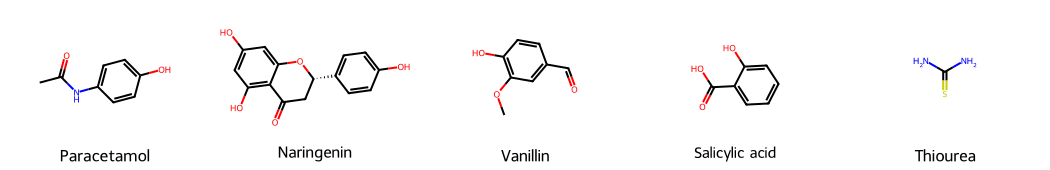

In [4]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, Crippen, rdMolDescriptors

example_mols = [Chem.MolFromSmiles(s) for s in examples.canonical_smiles]
grid = Draw.MolsToGridImage(example_mols, molsPerRow=5, subImgSize=(210,170),
                           legends=examples.name.tolist(), useSVG=True)
display(grid if hasattr(grid, "_repr_svg_") else SVG(grid))

## 2. SMILES에서 숫자 특징 6개 계산

**분자 구조 → SMILES 문자열 → RDKit → 숫자 벡터**

Paracetamol의 SMILES는 `CC(=O)Nc1ccc(O)cc1`입니다. 분자 이름 자체를 모델 입력으로 쓰지 않습니다.

| 특성 | 의미 |
|---|---|
| MolWt | 분자량, g/mol |
| MolLogP | 친유성과 관련된 계산 로그 분배계수 |
| TPSA | 위상학적 극성 표면적, Å² |
| NumHDonors | 수소결합 공여체 수 |
| NumRotatableBonds | 회전 가능한 결합 수 |
| RingCount | 고리 수 |

In [5]:
def molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"유효하지 않은 SMILES: {smiles}")
    return [Descriptors.MolWt(mol), Crippen.MolLogP(mol), rdMolDescriptors.CalcTPSA(mol),
            rdMolDescriptors.CalcNumHBD(mol), rdMolDescriptors.CalcNumRotatableBonds(mol),
            rdMolDescriptors.CalcNumRings(mol)]

computed = np.asarray([molecular_features(s) for s in data.canonical_smiles], dtype=np.float64)
descriptor_max_error = float(np.max(np.abs(computed - data[FEATURES].to_numpy(float))))
if not np.allclose(computed, data[FEATURES].to_numpy(float), atol=1e-7, rtol=1e-10):
    raise RuntimeError("RDKit 특성이 배포본과 다릅니다. requirements-verified.txt의 RDKit 버전으로 확인하세요.")

para = examples[examples.name.eq("Paracetamol")].iloc[0]
display(pd.DataFrame({"feature":FEATURES, "meaning":FEATURE_LABELS,
                      "Paracetamol":molecular_features(para.canonical_smiles)}).round(3))
print("입력 벡터 x =", np.round(molecular_features(para.canonical_smiles), 3))
print("554개 분자 전체를 SMILES에서 다시 계산했습니다.")

,feature,meaning,Paracetamol
0,MolWt,Molecular weight,151.165
1,MolLogP,MolLogP,1.351
2,TPSA,TPSA,49.330
3,NumHDonors,H-bond donors,2.000
4,NumRotatableBonds,Rotatable bonds,1.000
5,RingCount,Ring count,1.000


입력 벡터 x = [151.165   1.351  49.33    2.      1.      1.   ]
554개 분자 전체를 SMILES에서 다시 계산했습니다.


## 3. 선형 회귀 맛보기: 분자량으로 직선 맞추기

먼저 앞의 **실제 분자 5개**만으로 아이디어를 봅니다. 가로축은 분자량, 세로축은 로그 용해도입니다.
직선 $\hat y = a\times\mathrm{MolWt}+b$의 기울기와 절편을 맞춥니다.

**이 그림은 개념 설명용입니다.** 아래의 최종 성능 비교는 이 5개 분자 모델이 아니라,
특성 6개와 개발 분자 443개로 학습한 Ridge 모델을 사용합니다.

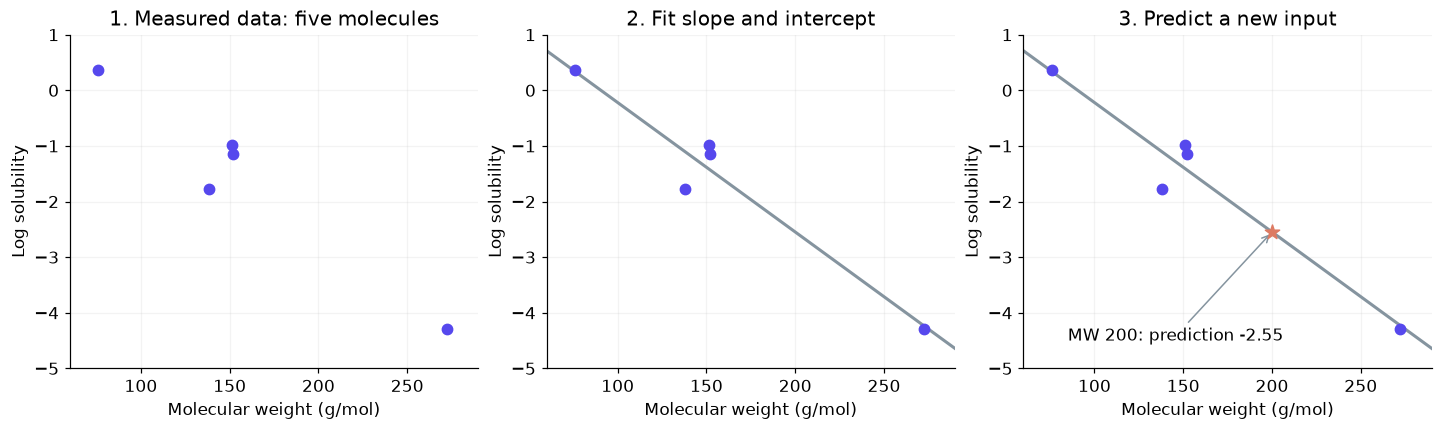

개념 설명용 직선: y_hat = -0.02328 × MolWt + 2.107


In [6]:
toy_X = examples[["MolWt"]].to_numpy(float)
toy_y = examples.y.to_numpy(float)
toy_model = LinearRegression().fit(toy_X, toy_y)
line_x = np.linspace(60, 290, 160)
new_weight = 200.0
toy_prediction = float(toy_model.predict([[new_weight]])[0])

fig, axes = plt.subplots(1, 3, figsize=(13,3.8), constrained_layout=True)
for ax in axes:
    ax.scatter(toy_X[:,0], toy_y, c=PURPLE, s=45, zorder=3)
    ax.set(xlabel="Molecular weight (g/mol)", ylabel="Log solubility", xlim=(60,290), ylim=(-5,1))
    ax.grid(alpha=.15)
axes[0].set_title("1. Measured data: five molecules")
axes[1].set_title("2. Fit slope and intercept")
axes[2].set_title("3. Predict a new input")
for ax in axes[1:]:
    ax.plot(line_x, toy_model.predict(line_x[:,None]), c=GRAY, lw=2)
axes[2].scatter([new_weight],[toy_prediction], c=ORANGE, s=95, marker="*", zorder=5)
axes[2].annotate(f"MW 200: prediction {toy_prediction:.2f}", (new_weight,toy_prediction),
                 xytext=(85,-4.5), arrowprops={"arrowstyle":"->", "color":GRAY})
fig.savefig(OUT/"01_linear_regression_intuition.png", dpi=160)
plt.show()
print(f"개념 설명용 직선: y_hat = {toy_model.coef_[0]:.5f} × MolWt + {toy_model.intercept_:.3f}")

## 4. 선형 Ridge 학습: 특성 6개와 개발 분자 443개

기존 실험의 분할을 그대로 사용합니다. **개발 443개 / 평가 111개**이며,
같은 분자 연결 구조가 두 부분에 겹치지 않습니다.
특성의 평균·표준편차는 **개발 데이터에서만** 계산하고 평가 데이터에는 그대로 적용합니다.

$$\hat y=b+w_1z_1+\cdots+w_6z_6$$

$z_j$는 표준화한 분자 특성입니다. Ridge는 큰 회귀 계수에 벌점을 주며,
개발 데이터에서 이미 선택한 `alpha=10`을 사용합니다. 이 실습에서는 튜닝을 다시 하지 않습니다.

In [7]:
train_idx = np.flatnonzero(data.split.eq("development").to_numpy())
test_idx = np.flatnonzero(data.split.eq("holdout").to_numpy())
dev, test = data.iloc[train_idx].reset_index(drop=True), data.iloc[test_idx].reset_index(drop=True)
assert (len(dev),len(test)) == (443,111)
assert not set(dev.connectivity_smiles).intersection(test.connectivity_smiles)
X_train, X_test = computed[train_idx], computed[test_idx]
y_train, y_test = dev.y.to_numpy(float), test.y.to_numpy(float)
input_scaler = StandardScaler().fit(X_train)
Z_train, Z_test = input_scaler.transform(X_train), input_scaler.transform(X_test)

linear_model = Ridge(alpha=protocol["linear_alpha"], solver="svd").fit(Z_train, y_train)
pred_linear = linear_model.predict(Z_test)

def scores(actual, predicted):
    return {"RMSE":float(np.sqrt(mean_squared_error(actual,predicted))),
            "MAE":float(mean_absolute_error(actual,predicted)),
            "R2":float(r2_score(actual,predicted))}

print("개발 입력:",Z_train.shape, "평가 입력:",Z_test.shape)
display(pd.DataFrame({"feature":FEATURES, "coefficient":linear_model.coef_}).round(4))
display(pd.DataFrame([{"model":"Linear Ridge", **scores(y_test,pred_linear)}]).round(3))

개발 입력: (443, 6) 평가 입력: (111, 6)


,feature,coefficient
0,MolWt,0.0473
1,MolLogP,-1.0296
2,TPSA,-0.7492
3,NumHDonors,0.2332
4,NumRotatableBonds,0.4874
5,RingCount,-0.5375


,model,RMSE,MAE,R2
0,Linear Ridge,1.285,1.027,0.522


### 발표와 연결: Paracetamol의 예측을 분해하기

기준값(절편)에 각 특성의 기여도 `표준화한 값 × 계수`를 더합니다.
이 예시는 모델 동작 설명용 개발 분자입니다. 평가 성능은 별도의 111개 분자로 계산합니다.

,feature,standardized value,coefficient,contribution
0,MolWt,-0.7513,0.0473,-0.0355
1,MolLogP,0.0903,-1.0296,-0.0930
2,TPSA,-0.7370,-0.7492,0.5522
3,NumHDonors,0.0194,0.2332,0.0045
4,NumRotatableBonds,-0.7281,0.4874,-0.3549
5,RingCount,-0.6013,-0.5375,0.3232


절편 -2.106 + 특성 기여도 합 +0.396 = 예측 -1.709
이 분자의 데이터 정답: -0.989


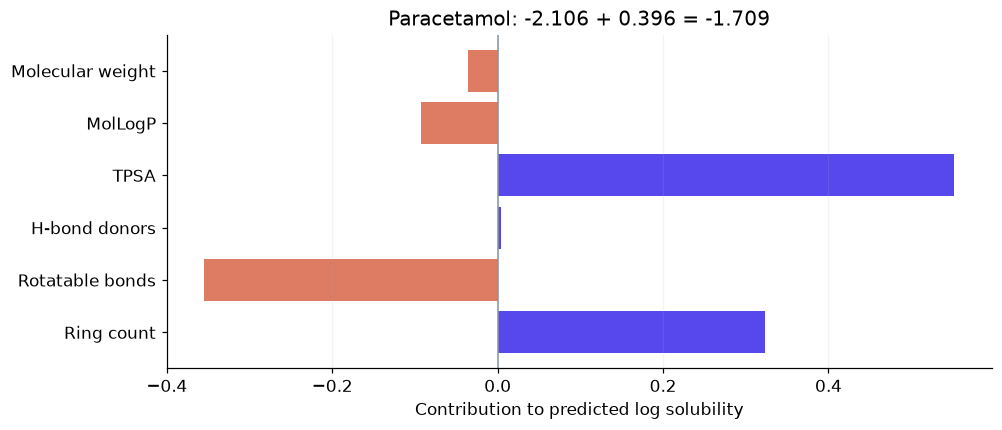

In [8]:
example_X = examples[FEATURES].to_numpy(float)
example_Z = input_scaler.transform(example_X)
para_index = EXAMPLE_NAMES.index("Paracetamol")
contributions = example_Z[para_index] * linear_model.coef_
para_prediction = float(linear_model.predict(example_Z[[para_index]])[0])
display(pd.DataFrame({"feature":FEATURES, "standardized value":example_Z[para_index],
                      "coefficient":linear_model.coef_, "contribution":contributions}).round(4))
print(f"절편 {linear_model.intercept_:.3f} + 특성 기여도 합 {contributions.sum():+.3f} = 예측 {para_prediction:.3f}")
print(f"이 분자의 데이터 정답: {para.y:.3f}")

fig, ax = plt.subplots(figsize=(9,3.8), constrained_layout=True)
ax.barh(FEATURE_LABELS, contributions, color=[PURPLE if v>=0 else ORANGE for v in contributions])
ax.axvline(0,c=GRAY,lw=1); ax.invert_yaxis()
ax.set(xlabel="Contribution to predicted log solubility", title=f"Paracetamol: {linear_model.intercept_:.3f} + {contributions.sum():.3f} = {para_prediction:.3f}")
ax.grid(axis="x",alpha=.15)
fig.savefig(OUT/"02_linear_contributions.png",dpi=160)
plt.show()

## 5. 광자 회로 만들기: 6개 특징을 입력 위상으로 변환

**같은 분자 특성 6개 → MZI의 위상 18개 → 광자 검출 확률 56개**

- 6모드: 광자가 지나는 경로 6개. **6큐비트라는 뜻은 아닙니다.**
- 3광자 입력: $|1,1,1,0,0,0\rangle$
- 데이터 MZI 9개를 3층으로 배치하고 층 사이에 고정 혼합 MZI 4개를 둡니다.
- 3광자를 6모드에 나누는 패턴은 $\binom{6+3-1}{3}=56$개입니다. 같은 모드에 광자가 모이는 경우도 포함합니다.

$$\theta_j(x)=\mathrm{offset}_j+\mathrm{scale}\times\mathrm{weight}_{f(j)}\times z_{f(j)}$$

회로 연결·특성 배치·scale·offset은 개발 데이터에서 선택한 값으로 고정합니다.
**분자가 바뀌면 입력 위상이 바뀝니다.** 여기서 얻는 확률은 광자 검출 패턴의 확률이며 분자가 물에 녹을 확률이 아닙니다.

회로는 Perceval, 확률 계산은 MerLin을 사용합니다. 아래 구현은 접혀 있으므로 처음에는 결과 그림부터 살펴보세요.

Perceval 1.3.1 | MerLin 0.4.2
고정 회로 준비: 6모드, 3광자, 3층, 출력 56개


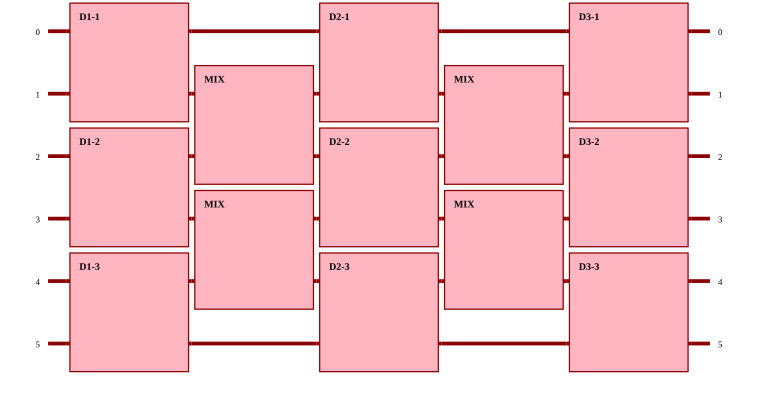

In [9]:
import torch
import perceval as pcvl
from merlin.algorithms import QuantumLayer
from merlin.measurement import MeasurementStrategy
from merlin.core.computation_space import ComputationSpace

torch.set_num_threads(1)
cfg = encoding["config"]
phase_indices = np.asarray(encoding["phase_feature_indices"], dtype=int)
offsets = np.asarray(encoding["phase_offsets_rad"], dtype=np.float64)
weights = np.asarray(encoding["feature_weights"], dtype=np.float64)

def mzi(theta, phi, name="MZI"):
    return (pcvl.Circuit(2, name=name).add(0, pcvl.BS.H()).add(0, pcvl.PS(theta))
            .add(0, pcvl.BS.H()).add(0, pcvl.PS(phi)))

def build_circuit(phases=None, grouped=False):
    circuit = pcvl.Circuit(6, name="Molecular photonic feature map")
    count = 0
    for depth in range(3):
        if depth > 0:
            for port in [1,3]:
                circuit.add(port,mzi(cfg["mix_angle"],cfg["mix_phase"],"Mix"),merge=not grouped)
        for gate,port in enumerate([0,2,4]):
            a,b = (pcvl.P(f"x{count:03d}"),pcvl.P(f"x{count+1:03d}")) if phases is None else phases[count:count+2]
            circuit.add(port,mzi(a,b,f"D{depth+1}-{gate+1}"),merge=not grouped)
            count += 2
    return circuit

circuit = build_circuit()
assert [p.name for p in circuit.get_parameters()] == [f"x{i:03d}" for i in range(18)]
quantum_layer = QuantumLayer(circuit=circuit, input_state=encoding["input_state"], input_size=18,
    input_parameters=["x"], trainable_parameters=[],
    measurement_strategy=MeasurementStrategy.probs(computation_space=ComputationSpace.FOCK),
    dtype=torch.float64, device=torch.device("cpu"))
quantum_layer.eval()
for parameter in quantum_layer.parameters():
    parameter.requires_grad_(False)

def encode_phases(standardized_features):
    return np.asarray(standardized_features[:,phase_indices] * weights[phase_indices]
                      * cfg["scale"] + offsets, dtype=np.float64)

def probability_features(standardized_features, batch_size=64):
    phases = encode_phases(standardized_features)
    blocks=[]
    with torch.inference_mode():
        for start in range(0,len(phases),batch_size):
            blocks.append(quantum_layer(torch.from_numpy(phases[start:start+batch_size])).cpu().numpy())
    result=np.vstack(blocks)
    assert result.shape == (len(phases),56)
    assert result.min()>=-1e-12
    assert np.allclose(result.sum(axis=1),1,atol=1e-9,rtol=0)
    return result

print("Perceval",metadata.version("perceval-quandela"),"| MerLin",metadata.version("merlinquantum"))
print("고정 회로 준비: 6모드, 3광자, 3층, 출력 56개")
pcvl.pdisplay(build_circuit(grouped=True), output_format=pcvl.Format.HTML, recursive=False)

In [10]:
example_phases=encode_phases(example_Z)
phase_table=pd.DataFrame({"phase":[f"theta_{i+1}" for i in range(18)],
                          "encoded feature":[FEATURES[j] for j in phase_indices],
                          "Paracetamol (rad)":example_phases[0], "Naringenin (rad)":example_phases[1]})
display(phase_table.head(6).round(4))
print("각 분자의 첫 6개 위상을 표시했습니다. 전체는 example_phases에 있습니다.")

,phase,encoded feature,Paracetamol (rad),Naringenin (rad)
0,theta_1,MolLogP,1.9675,2.0498
1,theta_2,RingCount,2.7749,2.8524
2,theta_3,MolWt,1.3871,1.5204
3,theta_4,TPSA,5.5041,5.5467
4,theta_5,NumHDonors,0.7607,0.8310
5,theta_6,NumRotatableBonds,5.3685,5.3685


각 분자의 첫 6개 위상을 표시했습니다. 전체는 example_phases에 있습니다.


## 6. 양자 특징 추출: 분자마다 달라지는 56개 확률

모든 분자에 **같은 회로와 인코딩 규칙**을 적용합니다.
한 행이 분자 하나, 한 열이 검출 패턴 하나인 확률 행렬을 만듭니다.

왼쪽의 분자 특성 행렬 $(443,6)$이 회로를 거쳐 새로운 특징 행렬 $(443,56)$이 됩니다.
GPU가 없어도 실행 가능한 작은 회로입니다. 실제 QPU에서는 반복 측정으로 추정할 확률을 여기서는 시뮬레이터로 계산합니다.

In [11]:
started=time.perf_counter()
P_train=probability_features(Z_train)
P_test=probability_features(Z_test)
P_examples=probability_features(example_Z)
feature_seconds=time.perf_counter()-started
keys=[tuple(int(v) for v in key) for key in quantum_layer.output_keys]
assert len(keys)==56 and len(set(keys))==56
print(f"특징 추출 완료: {feature_seconds:.2f}초")
print("개발:",Z_train.shape,"→",P_train.shape,"| 평가:",Z_test.shape,"→",P_test.shape)
display(pd.DataFrame({"pattern ID":np.arange(1,7), "detected photon counts":keys[:6],
                      "Paracetamol":P_examples[0,:6], "Naringenin":P_examples[1,:6]}).round(5))

특징 추출 완료: 0.01초
개발: (443, 6) → (443, 56) | 평가: (111, 6) → (111, 56)


,pattern ID,detected photon counts,Paracetamol,Naringenin
0,1,"(3, 0, 0, 0, 0, 0)",0.07598,0.05615
1,2,"(2, 1, 0, 0, 0, 0)",0.07643,0.08584
2,3,"(2, 0, 1, 0, 0, 0)",0.01663,0.03056
3,4,"(2, 0, 0, 1, 0, 0)",0.04127,0.05787
4,5,"(2, 0, 0, 0, 1, 0)",0.03955,0.02772
5,6,"(2, 0, 0, 0, 0, 1)",0.00444,0.00194


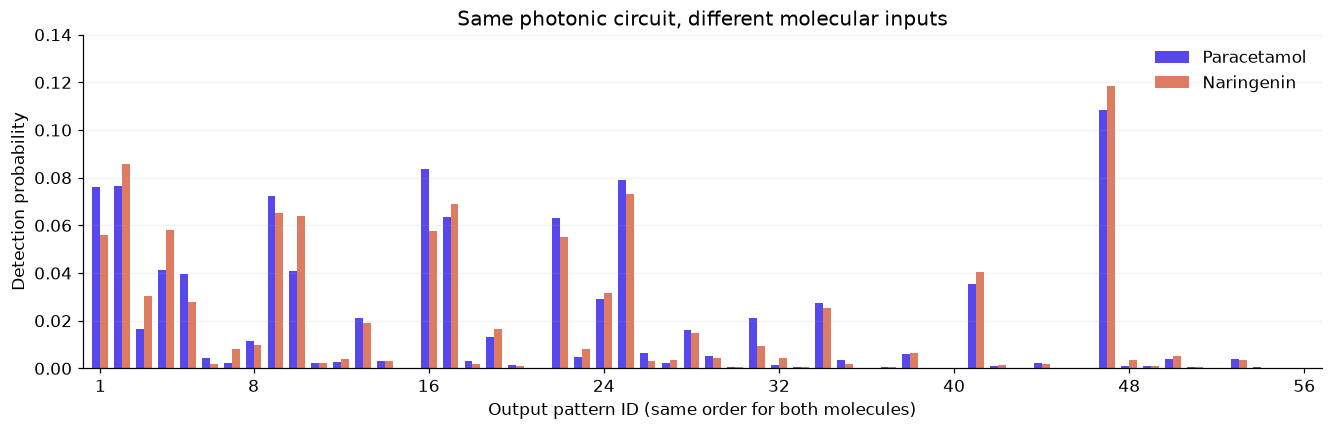

확률 합: {'Paracetamol': np.float64(1.0), 'Naringenin': np.float64(1.0)}


In [12]:
pattern_numbers=np.arange(1,57)
fig,ax=plt.subplots(figsize=(12,3.8),constrained_layout=True)
ax.bar(pattern_numbers-.18,P_examples[0],width=.36,color=PURPLE,label="Paracetamol")
ax.bar(pattern_numbers+.18,P_examples[1],width=.36,color=ORANGE,label="Naringenin")
ax.set(xlabel="Output pattern ID (same order for both molecules)",ylabel="Detection probability",
       title="Same photonic circuit, different molecular inputs",xlim=(.2,56.8),ylim=(0,.14))
ax.set_xticks([1,8,16,24,32,40,48,56]);ax.grid(axis="y",alpha=.15);ax.legend(frameon=False)
fig.savefig(OUT/"03_molecular_probability_features.png",dpi=160)
plt.show()
print("확률 합:",dict(zip(EXAMPLE_NAMES[:2],P_examples[:2].sum(axis=1).round(12))))

## 7. 광자 확률 특징으로 회귀 학습

| 비교 | 선형 Ridge | 광자 확률 + Ridge |
|---|---|---|
| 출발 입력 | 같은 분자 특성 6개 | 같은 분자 특성 6개 |
| 회귀에 넣는 특징 | 표준화한 특성 6개 | 광자 검출 확률 56개 |
| 학습하는 부분 | 회귀 계수와 절편 | 회귀 계수와 절편 |

$$\text{선형: }\hat y=b+\sum_{j=1}^{6}w_jz_j$$
$$\text{광자 특징: }\hat y=c+\sum_{k=1}^{56}v_kp_k(x)$$

**광자 회로는 고정된 특징 변환, 마지막 Ridge는 학습 가능한 예측 모형입니다.**
확률은 개발 데이터의 평균만 빼고 분산 표준화는 하지 않습니다. 개발 데이터에서 선택한 `alpha=1e-5`를 사용합니다.
화면의 $c$는 평균 제거를 흡수한 절편입니다. 두 모델은 특징 수와 alpha가 다르며 파라미터 수나 탐색 예산을 맞춘 비교가 아닙니다.

In [13]:
probability_centerer=StandardScaler(with_std=False).fit(P_train)
reservoir_model=Ridge(alpha=protocol["reservoir_alpha"],solver="svd")
reservoir_model.fit(probability_centerer.transform(P_train),y_train)
pred_reservoir=reservoir_model.predict(probability_centerer.transform(P_test))
effective_intercept=float(reservoir_model.intercept_-reservoir_model.coef_@probability_centerer.mean_)
assert np.allclose(effective_intercept+P_test@reservoir_model.coef_,pred_reservoir,atol=1e-9,rtol=0)
assert not any(parameter.requires_grad for parameter in quantum_layer.parameters())
print("학습한 회귀 계수:",reservoir_model.coef_.size,"개 + 절편")
print("광자 회로의 gradient 학습: 없음")
display(pd.DataFrame({"pattern ID":np.arange(1,7),"probability coefficient":reservoir_model.coef_[:6]}).round(4))

학습한 회귀 계수: 56 개 + 절편
광자 회로의 gradient 학습: 없음


,pattern ID,probability coefficient
0,1,-84.3449
1,2,-19.3527
2,3,-153.3455
3,4,-120.1816
4,5,-8.3496
5,6,61.2377


## 8. 발표와 같은 평가: 실제값–예측값 산점도

동일한 평가 분자 **111개**, 동일한 축 **−8부터 2**를 사용합니다.
회색 대각선은 실제값과 예측값이 같은 지점입니다.

- **RMSE**: 대표적인 예측 오차 크기, 작을수록 좋습니다.
- **R²**: 실제값의 변동을 얼마나 설명하는지 나타냅니다. 1에 가까울수록 좋으며 분류 정답률이 아닙니다.

,model,RMSE,MAE,R2
0,Linear Ridge,1.285,1.027,0.522
1,Photonic reservoir + Ridge,1.202,0.953,0.582


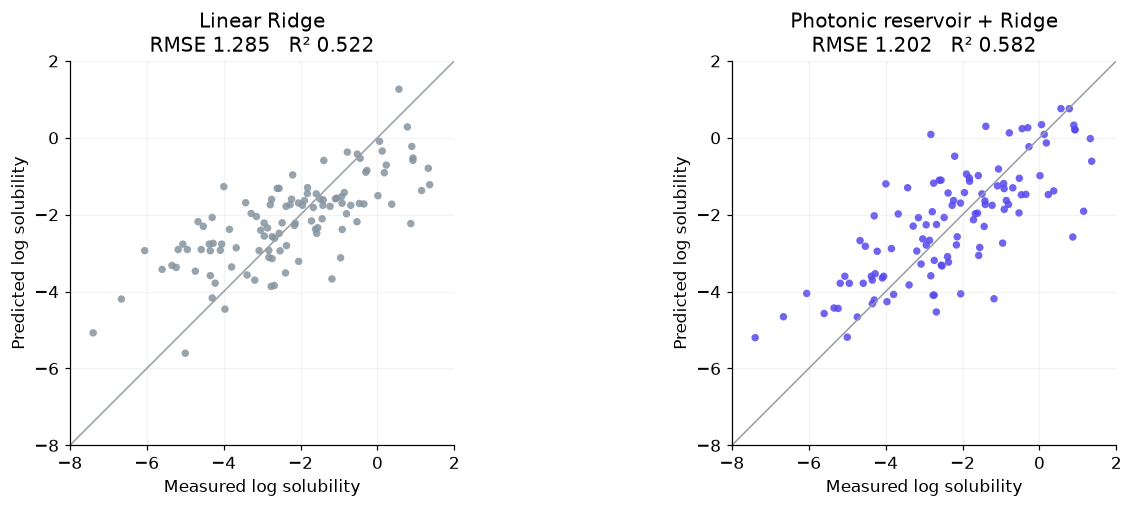

이번 평가에서 RMSE 6.49% 감소. 절대오차가 작은 분자는 65/111개.


In [14]:
results=pd.DataFrame([
    {"model":"Linear Ridge",**scores(y_test,pred_linear)},
    {"model":"Photonic reservoir + Ridge",**scores(y_test,pred_reservoir)}])
display(results.round(3))

fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for ax,label,pred,color in zip(axes,results.model,[pred_linear,pred_reservoir],[GRAY,PURPLE]):
    ax.scatter(y_test,pred,c=color,s=24,alpha=.85,edgecolors="none")
    ax.plot([-8,2],[-8,2],c="#969DA6",lw=1)
    score=scores(y_test,pred)
    ax.set(xlim=(-8,2),ylim=(-8,2),xlabel="Measured log solubility",ylabel="Predicted log solubility",
           title=f"{label}\nRMSE {score['RMSE']:.3f}   R² {score['R2']:.3f}")
    ax.set_xticks(np.arange(-8,3,2));ax.set_yticks(np.arange(-8,3,2));ax.set_aspect("equal")
    ax.grid(alpha=.15)
fig.savefig(OUT/"04_prediction_comparison.png",dpi=180)
plt.show()
reduction=100*(1-results.loc[1,"RMSE"]/results.loc[0,"RMSE"])
better_count=int(np.sum(np.abs(pred_reservoir-y_test)<np.abs(pred_linear-y_test)))
print(f"이번 평가에서 RMSE {reduction:.2f}% 감소. 절대오차가 작은 분자는 {better_count}/111개.")

## 9. 재현 확인과 결과 저장

지금까지 학습과 예측을 마친 후에만 저장된 기준 예측을 엽니다.
이 값은 정답·입력·학습 목표를 만드는 데 사용하지 않았습니다.
패키지별 수치 차이를 고려해 최대 예측 차이 `1e-5` 이내인지 확인합니다.

In [15]:
reference=pd.read_csv(BytesIO(asset_bytes("reference_predictions.csv")))
assert reference.canonical_smiles.tolist()==test.canonical_smiles.tolist()
assert np.allclose(reference.y,y_test,atol=1e-10,rtol=0)
linear_error=float(np.max(np.abs(pred_linear-reference.prediction_linear)))
reservoir_error=float(np.max(np.abs(pred_reservoir-reference.prediction_reservoir)))
reproduced=linear_error<1e-5 and reservoir_error<1e-5
if not reproduced:
    raise RuntimeError(f"기준 예측과 차이가 큽니다. 선형={linear_error:.3g}, reservoir={reservoir_error:.3g}. 검증 버전 환경에서 확인하세요.")

predictions=test[["name","canonical_smiles","y"]].copy()
predictions["prediction_linear"]=pred_linear
predictions["prediction_reservoir"]=pred_reservoir
predictions.to_csv(OUT/"predictions.csv",index=False)
results.to_csv(OUT/"comparison.csv",index=False)
pd.DataFrame(P_train,columns=[str(k) for k in keys]).to_csv(OUT/"development_probability_features.csv",index=False)
versions={name:metadata.version(name) for name in ["numpy","pandas","scipy","scikit-learn","torch",
          "perceval-quandela","merlinquantum","rdkit","matplotlib"]}
verification={"molecules":554,"development":443,"evaluation":111,"input_features":6,"probability_features":56,
    "linear_prediction_max_error":linear_error,"reservoir_prediction_max_error":reservoir_error,
    "descriptor_max_error":descriptor_max_error,"probability_sum_max_error":float(np.max(np.abs(P_train.sum(axis=1)-1))),
    "reproduced":reproduced,"qpu_jobs_submitted":0,"quantum_circuit_trained":False,
    "feature_extraction_seconds":feature_seconds,"python":sys.version.split()[0],"versions":versions,
    "asset_sha256":{name:info["sha256"] for name,info in BUNDLED_FILES.items()},"results":results.to_dict("records")}
(OUT/"reproduction_check.json").write_text(json.dumps(verification,indent=2),encoding="utf-8")
display(pd.DataFrame([{"model":"Linear Ridge","max prediction difference":linear_error},
                      {"model":"Photonic reservoir","max prediction difference":reservoir_error}]))
print("재현 확인 완료. outputs/에 그림 4개와 예측표·성능표·확률 특징·실행 기록을 저장했습니다.")

,model,max prediction difference
0,Linear Ridge,5.462297e-14
1,Photonic reservoir,4.707346e-14


재현 확인 완료. outputs/에 그림 4개와 예측표·성능표·확률 특징·실행 기록을 저장했습니다.


## 정리와 해석 범위

**분자 구조 → SMILES → 특성 6개 → 입력 위상 → 확률 56개 → 회귀 예측**

이번 평가에서 선형 Ridge의 RMSE는 약 **1.285**, 광자 특징 기반 Ridge는 **1.202**입니다.
이는 이 데이터와 설정에서의 관찰입니다. 더 강력한 고전 비선형 모델도 있으며,
기존 RBF 결과의 RMSE는 **1.182**였습니다. 양자 우위나 일반적인 우수성을 입증하지 않습니다.

기존 평가 분할을 재사용한 후속 실험이며, 고정 예측에 대한 paired conditional bootstrap의
RMSE 차이(reservoir−linear) 95% 구간은 **[−0.207, 0.047]**로 0을 포함했습니다.
이 구간에는 회로 선택·재학습의 불확실성이 포함되지 않습니다.
현재는 이상적 시뮬레이션이며, 실제 QPU의 shots·손실·위상 오차·검출기 잡음은 반영하지 않았습니다.

### 직접 해보기

1. 3절의 `new_weight`를 바꾸면 직선의 예측값은 어떻게 달라지나요?
2. 확률 그래프에서 같은 패턴 번호의 두 막대를 비교해 보세요. 각 분포의 합은 얼마인가요?
3. `examples`에서 다른 분자를 골라 회로 출력과 예측을 살펴보세요.

최종 성능을 그대로 재현하려면 회로·분할·전처리·alpha를 유지하세요.
평가 점수에 맞춰 설정을 바꾸는 탐색은 새로운 독립 검증이 아닙니다.

**더 알아보기:** [Quandela Hub](https://hub.quandela.com/) ·
[Cloud Web IDE](https://cloud.quandela.com/webide) ·
[MerLin 문서](https://merlinquantum.ai/0.4/) · [Perceval 문서](https://perceval.quandela.net/).
Hub/Cloud의 로그인·커널 제공·설치 권한은 계정 환경에 따라 확인해야 합니다.

### 출처와 이용 조건

Data: Krasnov, Malikov, Kiseleva, Tatarin, Sosnin & Bezzubov, *BigSolDB 2.2* (2026),
[Zenodo DOI](https://doi.org/10.5281/zenodo.22648301), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
관련 논문: [doi:10.1038/s41597-025-05559-8](https://doi.org/10.1038/s41597-025-05559-8).
Changes: filtered to water at 298.15 K and equilibrium methods, aggregated by canonical isomeric SMILES
using median reported log solubility, calculated RDKit descriptors, and added a fixed split.
모델 예측과 그림은 이 세미나의 자체 분석 결과이며 원저자의 후원이나 보증을 뜻하지 않습니다.